# COMP9414 Assignment 2: Collaborative Multi-Agent Reinforcement Learning

IPPO vs MAPPO on a 12x12 cooperative cleaning grid world with 3 agents.
The notebook is organised by task (1 to 5); each requirement/deliverable is
its own cell so results can be checked independently.

In [1]:
# Requirements
# pip install torch numpy matplotlib
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

print("numpy", np.__version__, "| torch", torch.__version__)

numpy 1.26.4 | torch 2.3.0+cpu


## Task 1: Environment for Multi-Agent Reinforcement Learning

12x12 grid, 3 agents, fragile objects, normal/large dirt, a fixed-position
mode and a random-dirt mode. Coordinates in the spec are 1-indexed; they are
converted to 0-indexed on construction. Reward values follow Table 2.

In [2]:
def to_zero_indexed(coords):
    return np.array([(r - 1, c - 1) for r, c in coords], dtype=int)


class CleaningGridWorld:
    """12x12 cooperative cleaning grid world with 3 agents, Gymnasium-style API."""

    N_AGENTS = 3
    GRID = 12
    MAX_STEPS = 50

    ACTIONS = {0: "IDLE", 1: "UP", 2: "DOWN", 3: "LEFT", 4: "RIGHT"}
    ACTION_DELTA = {0: (0, 0), 1: (-1, 0), 2: (1, 0), 3: (0, -1), 4: (0, 1)}

    START_POS_RAW = [(1, 3), (12, 3), (7, 12)]
    FRAGILE_RAW = [(2, 2), (4, 4), (6, 6), (7, 2), (8, 4), (10, 6),
                   (1, 7), (4, 7), (8, 7), (12, 7),
                   (3, 11), (8, 9), (6, 10), (11, 11)]
    LARGE_DIRT_RAW = [(2, 5), (3, 9), (4, 2), (6, 7), (8, 8), (9, 4), (10, 11), (12, 2)]
    NORMAL_DIRT_RAW = [(1, 4), (1, 10), (3, 2), (4, 8), (5, 9), (7, 3), (9, 11), (12, 6)]

    R_NORMAL_DIRT = 2.0
    R_LARGE_DIRT = 4.0
    R_NEW_CELL = 2.0
    R_REVISIT = -1.0
    R_IDLE = -0.1
    R_TIMESTEP = -0.1
    R_COLLISION = -20.0
    R_COMPLETE = 20.0

    def __init__(self, random_dirt=False, seed=None):
        self.random_dirt = random_dirt
        self.rng = np.random.default_rng(seed)
        self._fragile = to_zero_indexed(self.FRAGILE_RAW)
        self._start = to_zero_indexed(self.START_POS_RAW)
        self._fragile_mask = np.zeros((self.GRID, self.GRID), dtype=bool)
        self._fragile_mask[self._fragile[:, 0], self._fragile[:, 1]] = True
        self.reset(seed=seed)

    def reset(self, seed=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)

        if self.random_dirt:
            self._large_dirt, self._normal_dirt = self._sample_dirt_positions()
        else:
            self._large_dirt = to_zero_indexed(self.LARGE_DIRT_RAW)
            self._normal_dirt = to_zero_indexed(self.NORMAL_DIRT_RAW)

        self.large_active = np.ones(len(self._large_dirt), dtype=bool)
        self.normal_active = np.ones(len(self._normal_dirt), dtype=bool)
        self.agent_pos = self._start.copy()
        self.explored = np.zeros((self.GRID, self.GRID), dtype=bool)
        for r, c in self.agent_pos:
            self.explored[r, c] = True
        self.t = 0

        obs = self._get_obs()
        info = {"large_dirt_active": self.large_active.copy(), "normal_dirt_active": self.normal_active.copy()}
        return obs, info

    def step(self, actions):
        actions = np.asarray(actions, dtype=int)
        self.t += 1
        rewards = np.full(self.N_AGENTS, self.R_TIMESTEP)
        proposed = self.agent_pos.copy()
        collided = np.zeros(self.N_AGENTS, dtype=bool)

        for i, a in enumerate(actions):
            if a == 0:
                # idle never triggers a revisit check, the agent stays in its own cell
                rewards[i] += self.R_IDLE
                continue
            dr, dc = self.ACTION_DELTA[a]
            nr, nc = self.agent_pos[i, 0] + dr, self.agent_pos[i, 1] + dc
            if not (0 <= nr < self.GRID and 0 <= nc < self.GRID):
                rewards[i] += self.R_COLLISION
                collided[i] = True
                continue  # safety shield: stay at old position
            if self._fragile_mask[nr, nc]:
                rewards[i] += self.R_COLLISION
                collided[i] = True
                continue  # safety shield: stay at old position
            proposed[i] = (nr, nc)

        # inter-agent collisions: same target cell or a head-on swap
        for i in range(self.N_AGENTS):
            for j in range(i + 1, self.N_AGENTS):
                same_target = tuple(proposed[i]) == tuple(proposed[j])
                swap = (tuple(proposed[i]) == tuple(self.agent_pos[j])
                        and tuple(proposed[j]) == tuple(self.agent_pos[i]))
                if same_target or swap:
                    for k in (i, j):
                        if not collided[k]:
                            rewards[k] += self.R_COLLISION
                            collided[k] = True
                    proposed[i], proposed[j] = self.agent_pos[i], self.agent_pos[j]

        self.agent_pos = proposed

        for i, (r, c) in enumerate(self.agent_pos):
            if collided[i]:
                continue
            if not self.explored[r, c]:
                self.explored[r, c] = True
                rewards[i] += self.R_NEW_CELL
            else:
                rewards[i] += self.R_REVISIT

            large_hit = np.where((self._large_dirt[:, 0] == r) & (self._large_dirt[:, 1] == c) & self.large_active)[0]
            if len(large_hit):
                self.large_active[large_hit[0]] = False
                rewards[i] += self.R_LARGE_DIRT
            normal_hit = np.where((self._normal_dirt[:, 0] == r) & (self._normal_dirt[:, 1] == c) & self.normal_active)[0]
            if len(normal_hit):
                self.normal_active[normal_hit[0]] = False
                rewards[i] += self.R_NORMAL_DIRT

        all_clean = (not self.large_active.any()) and (not self.normal_active.any())
        terminated = bool(all_clean)
        truncated = bool(collided.any()) or (self.t >= self.MAX_STEPS and not terminated)
        if terminated:
            rewards += self.R_COMPLETE

        obs = self._get_obs()
        info = {"collided": collided.copy(), "large_dirt_active": self.large_active.copy(),
                "normal_dirt_active": self.normal_active.copy(), "t": self.t}
        return obs, rewards, terminated, truncated, info

    def _get_obs(self):
        # channels: fragile map, self position, other agents, explored area, docking position
        explored_map = self.explored.astype(np.float32)
        obs = []
        for i in range(self.N_AGENTS):
            self_map = np.zeros((self.GRID, self.GRID), dtype=np.float32)
            self_map[self.agent_pos[i, 0], self.agent_pos[i, 1]] = 1.0
            other_map = np.zeros((self.GRID, self.GRID), dtype=np.float32)
            for j in range(self.N_AGENTS):
                if j != i:
                    other_map[self.agent_pos[j, 0], self.agent_pos[j, 1]] = 1.0
            dock_map = np.zeros((self.GRID, self.GRID), dtype=np.float32)
            dock_map[self._start[i, 0], self._start[i, 1]] = 1.0
            o_i = np.stack([self._fragile_mask.astype(np.float32), self_map, other_map, explored_map, dock_map], axis=-1)
            obs.append(o_i)
        return obs

    def get_global_state(self):
        return np.concatenate(self._get_obs(), axis=-1)

    def _sample_dirt_positions(self):
        occupied = set(map(tuple, self._fragile)) | set(map(tuple, self._start))
        free_cells = [(r, c) for r in range(self.GRID) for c in range(self.GRID) if (r, c) not in occupied]
        n_large, n_normal = len(self.LARGE_DIRT_RAW), len(self.NORMAL_DIRT_RAW)
        idx = self.rng.choice(len(free_cells), size=n_large + n_normal, replace=False)
        chosen = [free_cells[k] for k in idx]
        return np.array(chosen[:n_large]), np.array(chosen[n_large:])

    AGENT_COLORS = ["#e6c700", "#2ca02c", "#1f77b4"]

    def render(self, ax=None, title=None):
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 6))
        ax.clear()
        grid = np.ones((self.GRID, self.GRID, 3))
        for r, c in self._fragile:
            grid[r, c] = [0.86, 0.2, 0.2]
        for k, (r, c) in enumerate(self._large_dirt):
            if self.large_active[k]:
                grid[r, c] = [0.35, 0.35, 0.35]
        for k, (r, c) in enumerate(self._normal_dirt):
            if self.normal_active[k]:
                grid[r, c] = [0.75, 0.75, 0.75]

        ax.imshow(grid, extent=[0, self.GRID, self.GRID, 0])
        for i, (r, c) in enumerate(self.agent_pos):
            ax.scatter(c + 0.5, r + 0.5, s=500, marker="*", color=self.AGENT_COLORS[i], edgecolors="black", zorder=3)
        for i, (r, c) in enumerate(self._start):
            ax.scatter(c + 0.5, r + 0.5, s=150, marker="^", facecolors="none", edgecolors=self.AGENT_COLORS[i], zorder=2)

        ax.set_xticks(np.arange(0, self.GRID + 1, 1))
        ax.set_yticks(np.arange(0, self.GRID + 1, 1))
        ax.set_xticklabels(np.arange(1, self.GRID + 2, 1))
        ax.set_yticklabels(np.arange(1, self.GRID + 2, 1))
        ax.grid(True, color="grey", linewidth=0.5)
        ax.set_title(title or f"t={self.t}")
        legend = [mpatches.Patch(color="#dc3333", label="Fragile Object"),
                  mpatches.Patch(color="#bfbfbf", label="Normal Dirt"),
                  mpatches.Patch(color="#595959", label="Large Dirt")]
        legend += [mpatches.Patch(color=self.AGENT_COLORS[i], label=f"Agent {i+1}") for i in range(self.N_AGENTS)]
        ax.legend(handles=legend, bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
        return ax

Deliverable 2: visualize the grid world (fixed-position scenario, Table 1).

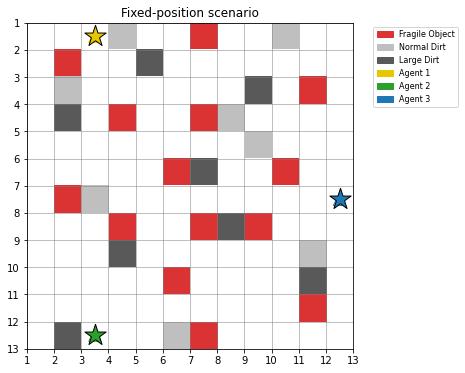

In [3]:
env = CleaningGridWorld(random_dirt=False, seed=0)
env.reset(seed=0)
env.render(title="Fixed-position scenario")
plt.show()

Deliverable 3: random-action rollout, printing per-agent state and reward at each step.

In [4]:
rng = np.random.default_rng(0)
env.reset(seed=0)
for t in range(5):
    actions = rng.integers(0, 5, size=env.N_AGENTS)
    obs, rewards, terminated, truncated, info = env.step(actions)
    for i in range(env.N_AGENTS):
        print(f"t={t} agent={i} action={env.ACTIONS[actions[i]]:<5} "
              f"pos={tuple(env.agent_pos[i])} obs_shape={obs[i].shape} reward={rewards[i]:.2f}")
    print(f"terminated={terminated} truncated={truncated}")
    if terminated or truncated:
        break

t=0 agent=0 action=RIGHT pos=(0, 3) obs_shape=(12, 12, 5) reward=3.90
t=0 agent=1 action=LEFT  pos=(11, 1) obs_shape=(12, 12, 5) reward=5.90
t=0 agent=2 action=DOWN  pos=(7, 11) obs_shape=(12, 12, 5) reward=1.90
terminated=False truncated=False
t=1 agent=0 action=UP    pos=(0, 3) obs_shape=(12, 12, 5) reward=-20.10
t=1 agent=1 action=UP    pos=(10, 1) obs_shape=(12, 12, 5) reward=1.90
t=1 agent=2 action=IDLE  pos=(7, 11) obs_shape=(12, 12, 5) reward=-1.20
terminated=False truncated=True


Deliverable 4: collision (fragile object, grid boundary, other robot) truncates the episode with the -20 penalty.

In [5]:
# fragile object
env.reset(seed=1)
env.step([2, 0, 0])
obs, r, term, trunc, info = env.step([3, 0, 0])  # agent 0 steps onto a fragile cell
print(f"fragile hit: reward={r[0]:.2f} truncated={trunc} collided={info['collided']}")
assert trunc and info["collided"][0]

# grid boundary
env.reset(seed=1)
obs, r, term, trunc, info = env.step([1, 0, 0])  # agent 0 already at row 0, UP goes out of bounds
print(f"out of bounds: reward={r[0]:.2f} truncated={trunc} collided={info['collided']}")
assert trunc and info["collided"][0]

# another robot: place two agents next to each other and have them swap places
env.reset(seed=1)
env.agent_pos[1] = np.array([5, 5])
env.agent_pos[2] = np.array([5, 6])
obs, r, term, trunc, info = env.step([0, 4, 3])  # agent1 RIGHT into agent2's cell, agent2 LEFT into agent1's cell
print(f"robot swap collision: reward1={r[1]:.2f} reward2={r[2]:.2f} truncated={trunc} collided={info['collided']}")
assert trunc and info["collided"][1] and info["collided"][2]
print("confirmed: fragile/boundary/robot collisions all truncate the episode with the -20 penalty")

fragile hit: reward=-20.10 truncated=True collided=[ True False False]
out of bounds: reward=-20.10 truncated=True collided=[ True False False]
robot swap collision: reward1=-20.10 reward2=-20.10 truncated=True collided=[False  True  True]
confirmed: fragile/boundary/robot collisions all truncate the episode with the -20 penalty


## Task 2: Modular PPO Pipeline Construction

Four sub-modules matching Algorithms 1-4: actor/critic networks, rollout
buffer, GAE estimator, and the PPO optimizer step. Each has its own test
cell below.

Actor and critic networks (MLP).

In [6]:
OBS_DIM = 12 * 12 * 5
N_ACTIONS = 5


def build_mlp(in_dim, out_dim, hidden_sizes):
    layers = []
    last = in_dim
    for h in hidden_sizes:
        layers += [nn.Linear(last, h), nn.Tanh()]
        last = h
    layers.append(nn.Linear(last, out_dim))
    return nn.Sequential(*layers)


class ActorNet(nn.Module):
    def __init__(self, obs_dim=OBS_DIM, n_actions=N_ACTIONS, hidden_sizes=(128, 128)):
        super().__init__()
        self.body = build_mlp(obs_dim, n_actions, hidden_sizes)

    def forward(self, obs):
        return Categorical(logits=self.body(obs))

    def act(self, obs):
        dist = self.forward(obs)
        action = dist.sample()
        return action, dist.log_prob(action), dist.entropy()

    def evaluate(self, obs, action):
        dist = self.forward(obs)
        return dist.log_prob(action), dist.entropy()


class CriticNet(nn.Module):
    def __init__(self, in_dim=OBS_DIM, hidden_sizes=(128, 128)):
        super().__init__()
        self.body = build_mlp(in_dim, 1, hidden_sizes)

    def forward(self, x):
        return self.body(x).squeeze(-1)


def build_ippo_networks(n_agents=3, hidden_sizes=(128, 128)):
    actors = [ActorNet(OBS_DIM, N_ACTIONS, hidden_sizes) for _ in range(n_agents)]
    critics = [CriticNet(OBS_DIM, hidden_sizes) for _ in range(n_agents)]
    return actors, critics


def build_mappo_networks(n_agents=3, hidden_sizes=(128, 128)):
    # shared actor takes local obs plus a one-hot agent id; critic takes the global state
    actor = ActorNet(OBS_DIM + n_agents, N_ACTIONS, hidden_sizes)
    critic = CriticNet(OBS_DIM * n_agents, hidden_sizes)
    return actor, critic

In [7]:
torch.manual_seed(0)
actor = ActorNet()
critic = CriticNet()
print(actor)
print(critic)

dummy_obs = torch.rand(4, OBS_DIM)
action, logp, entropy = actor.act(dummy_obs)
value = critic(dummy_obs)
print("action:", action.tolist())
print("log_prob:", [round(x, 3) for x in logp.tolist()])
print("entropy:", [round(x, 3) for x in entropy.tolist()])
print("value:", [round(x, 3) for x in value.tolist()])
print("actor params:", sum(p.numel() for p in actor.parameters()))
print("critic params:", sum(p.numel() for p in critic.parameters()))

ActorNet(
  (body): Sequential(
    (0): Linear(in_features=720, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)
CriticNet(
  (body): Sequential(
    (0): Linear(in_features=720, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)
action: [0, 3, 0, 2]
log_prob: [-1.634, -1.515, -1.545, -1.736]
entropy: [1.602, 1.606, 1.608, 1.605]
value: [-0.107, -0.011, -0.123, -0.027]
actor params: 109445
critic params: 108929


Rollout buffer (Algorithm 2) and GAE advantage estimator (Algorithm 3).

In [8]:
class RolloutBuffer:
    def __init__(self):
        self.reset()

    def reset(self):
        self.obs, self.value_inputs, self.actions = [], [], []
        self.log_probs, self.rewards, self.values, self.dones = [], [], [], []
        self.advantages, self.returns = None, None

    def add(self, obs, value_input, action, log_prob, reward, value, done):
        self.obs.append(obs)
        self.value_inputs.append(value_input)
        self.actions.append(action)
        self.log_probs.append(log_prob)
        self.rewards.append(reward)
        self.values.append(value)
        self.dones.append(done)

    def compute_gae(self, last_value, gamma=0.95, lam=0.95):
        T = len(self.rewards)
        values = np.asarray(self.values + [last_value], dtype=np.float32)
        rewards = np.asarray(self.rewards, dtype=np.float32)
        dones = np.asarray(self.dones, dtype=np.float32)

        advantages = np.zeros(T, dtype=np.float32)
        gae = 0.0
        for t in reversed(range(T)):
            mask = 1.0 - dones[t]
            delta = rewards[t] + gamma * values[t + 1] * mask - values[t]
            gae = delta + gamma * lam * mask * gae
            advantages[t] = gae
        returns = advantages + values[:T]
        self.advantages, self.returns = advantages, returns
        return advantages, returns

    def get_arrays(self):
        return {
            "obs": np.asarray(self.obs, dtype=np.float32),
            "value_inputs": np.asarray(self.value_inputs, dtype=np.float32),
            "actions": np.asarray(self.actions, dtype=np.int64),
            "log_probs": np.asarray(self.log_probs, dtype=np.float32),
            "rewards": np.asarray(self.rewards, dtype=np.float32),
            "values": np.asarray(self.values, dtype=np.float32),
            "advantages": self.advantages,
            "returns": self.returns,
        }

    def save_npz(self, path):
        np.savez(path, **self.get_arrays())


def collect_rollout(env, actors, critics, n_steps, use_global_state=False):
    """Algorithm 2. actors/critics can repeat the same shared module N times (MAPPO)
    or hold independent modules (IPPO)."""
    n_agents = env.N_AGENTS
    buffers = [RolloutBuffer() for _ in range(n_agents)]
    episode_records = []
    ep_return = np.zeros(n_agents)
    ep_len = 0

    obs_list, _ = env.reset()
    for _ in range(n_steps):
        flat_obs = [o.reshape(-1) for o in obs_list]
        global_state = env.get_global_state().reshape(-1) if use_global_state else None

        actions, log_probs, values = [], [], []
        for i in range(n_agents):
            o_t = torch.tensor(flat_obs[i], dtype=torch.float32).unsqueeze(0)
            if use_global_state:
                actor_in = torch.cat([o_t, torch.eye(n_agents)[i].unsqueeze(0)], dim=-1)
            else:
                actor_in = o_t
            with torch.no_grad():
                a, logp, _ = actors[i].act(actor_in)
                v_in = torch.tensor(global_state, dtype=torch.float32).unsqueeze(0) if use_global_state else o_t
                v = critics[i](v_in)
            actions.append(a.item())
            log_probs.append(logp.item())
            values.append(v.item())

        next_obs_list, rewards, terminated, truncated, info = env.step(actions)
        done = terminated or truncated
        ep_return += np.asarray(rewards)
        ep_len += 1

        for i in range(n_agents):
            value_input = global_state if use_global_state else flat_obs[i]
            buffers[i].add(flat_obs[i], value_input, actions[i], log_probs[i], float(rewards[i]), values[i], float(done))

        obs_list = next_obs_list
        if done:
            episode_records.append({"return": ep_return.copy(), "length": ep_len,
                                     "success": bool(terminated), "violation": bool(info["collided"].any())})
            ep_return[:] = 0.0
            ep_len = 0
            obs_list, _ = env.reset()

    return buffers, episode_records

Rollout buffer test: generate one rollout cycle from untrained networks, save it, print shapes.

In [9]:
actors, critics = build_ippo_networks(n_agents=env.N_AGENTS, hidden_sizes=(64, 64))
buffers, episode_records = collect_rollout(env, actors, critics, n_steps=20, use_global_state=False)

for i, buf in enumerate(buffers):
    adv, ret = buf.compute_gae(last_value=0.0, gamma=0.95, lam=0.95)
    arrs = buf.get_arrays()
    for k, v in arrs.items():
        print(f"agent {i} {k}: shape={v.shape} sample={np.round(v.flatten()[:3], 3)}")
    buf.save_npz(f"logs/task2_rollout_agent{i}.npz")
print(f"episodes completed in this 20-step rollout: {len(episode_records)}")

agent 0 obs: shape=(20, 720) sample=[0. 0. 0.]
agent 0 value_inputs: shape=(20, 720) sample=[0. 0. 0.]
agent 0 actions: shape=(20,) sample=[1 4 1]
agent 0 log_probs: shape=(20,) sample=[-1.652 -1.609 -1.652]
agent 0 rewards: shape=(20,) sample=[-20.1   3.9 -20.1]
agent 0 values: shape=(20,) sample=[-0.04 -0.04 -0.04]
agent 0 advantages: shape=(20,) sample=[-20.06   3.94 -20.06]
agent 0 returns: shape=(20,) sample=[-20.1   3.9 -20.1]
agent 1 obs: shape=(20, 720) sample=[0. 0. 0.]
agent 1 value_inputs: shape=(20, 720) sample=[0. 0. 0.]
agent 1 actions: shape=(20,) sample=[2 1 4]
agent 1 log_probs: shape=(20,) sample=[-1.662 -1.531 -1.604]
agent 1 rewards: shape=(20,) sample=[-20.1   1.9   1.9]
agent 1 values: shape=(20,) sample=[-0.063 -0.063 -0.063]
agent 1 advantages: shape=(20,) sample=[-20.037   1.963   1.963]
agent 1 returns: shape=(20,) sample=[-20.1   1.9   1.9]
agent 2 obs: shape=(20, 720) sample=[0. 0. 0.]
agent 2 value_inputs: shape=(20, 720) sample=[0. 0. 0.]
agent 2 actions: 

GAE bias/variance check: lambda near 0 gives low-variance/high-bias (TD-like) advantages, lambda near 1 gives high-variance/low-bias (Monte-Carlo-like) advantages.

In [10]:
buf = buffers[0]
for lam in [0.0, 0.5, 0.95, 1.0]:
    adv, _ = buf.compute_gae(last_value=0.0, gamma=0.95, lam=lam)
    print(f"lambda={lam:.2f} advantage mean={adv.mean():.3f} variance={adv.var():.3f}")
buf.compute_gae(last_value=0.0, gamma=0.95, lam=0.95)  # restore the value used for training

lambda=0.00 advantage mean=-2.259 variance=58.763
lambda=0.50 advantage mean=-2.899 variance=63.784
lambda=0.95 advantage mean=-3.840 variance=87.631
lambda=1.00 advantage mean=-3.967 variance=92.385


(array([-20.059553  ,   3.9404466 , -20.059553  ,   1.9404465 ,
          7.8643928 ,   4.3713336 ,   2.7563198 ,   0.9284375 ,
         -1.0548389 ,  -0.42618665,   0.84861386,  -1.1451762 ,
        -18.61642   , -19.31363   , -20.077267  ,   1.9404465 ,
          0.85612285,  -1.1721345 ,   0.85598195,  -1.1691675 ],
       dtype=float32),
 array([-20.1       ,   3.9       , -20.1       ,   1.9       ,
          7.823946  ,   4.3490357 ,   2.7157488 ,   0.9051048 ,
         -1.1       ,  -0.4666332 ,   0.81439584,  -1.2       ,
        -18.656868  , -19.34133   , -20.1       ,   1.9       ,
          0.8156763 ,  -1.2       ,   0.81553537,  -1.2       ],
       dtype=float32))

PPO optimizer module (Algorithm 4): probability ratio, clipped actor loss, critic loss, entropy bonus, total loss.

In [11]:
def probability_ratio(new_log_prob, old_log_prob):
    return torch.exp(new_log_prob - old_log_prob)


def clipped_actor_loss(ratio, advantages, epsilon=0.2):
    surr1 = ratio * advantages
    surr2 = torch.clamp(ratio, 1.0 - epsilon, 1.0 + epsilon) * advantages
    return -torch.min(surr1, surr2).mean()


def critic_loss_fn(values_new, returns):
    return ((values_new - returns) ** 2).mean()


def entropy_bonus_fn(entropy):
    return entropy.mean()


def total_loss_fn(l_clip, l_value, s_entropy, c1=0.5, c2=0.01):
    return l_clip + c1 * l_value - c2 * s_entropy


def ppo_update(actor, critic, actor_opt, critic_opt, batch, epsilon=0.2, c1=0.5, c2=0.01):
    obs, value_in = batch["obs"], batch["value_in"]
    actions, old_log_probs = batch["actions"], batch["old_log_probs"]
    advantages, returns = batch["advantages"], batch["returns"]

    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    new_log_probs, entropy = actor.evaluate(obs, actions)
    values_new = critic(value_in)

    ratio = probability_ratio(new_log_probs, old_log_probs)
    l_clip = clipped_actor_loss(ratio, advantages, epsilon)
    l_value = critic_loss_fn(values_new, returns)
    s_entropy = entropy_bonus_fn(entropy)
    loss = total_loss_fn(l_clip, l_value, s_entropy, c1, c2)

    actor_opt.zero_grad()
    critic_opt.zero_grad()
    loss.backward()
    actor_opt.step()
    critic_opt.step()

    return {"actor_loss": l_clip.item(), "critic_loss": l_value.item(),
            "entropy": s_entropy.item(), "total_loss": loss.item()}

Optimizer module test: run one PPO update on the saved rollout and print every computed value.

In [12]:
data = np.load("logs/task2_rollout_agent0.npz")
batch = {
    "obs": torch.tensor(data["obs"], dtype=torch.float32),
    "value_in": torch.tensor(data["value_inputs"], dtype=torch.float32),
    "actions": torch.tensor(data["actions"], dtype=torch.int64),
    "old_log_probs": torch.tensor(data["log_probs"], dtype=torch.float32),
    "advantages": torch.tensor(data["advantages"], dtype=torch.float32),
    "returns": torch.tensor(data["returns"], dtype=torch.float32),
}
test_actor, test_critic = ActorNet(), CriticNet()
opt_a = optim.Adam(test_actor.parameters(), lr=3e-4)
opt_c = optim.Adam(test_critic.parameters(), lr=3e-4)
losses = ppo_update(test_actor, test_critic, opt_a, opt_c, batch)
print("Algorithm 4 one-step losses:", losses)

D:\python\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Algorithm 4 one-step losses: {'actor_loss': 0.00042798518552444875, 'critic_loss': 102.93623352050781, 'entropy': 1.6078888177871704, 'total_loss': 51.45246505737305}


## Task 3: Independent Proximal Policy Optimization (IPPO)

Fully independent actor/critic per agent, no shared critic, no cross-agent
communication (Algorithm 1).

In [13]:
class IPPOTrainer:
    def __init__(self, random_dirt=False, hidden_sizes=(128, 128), lr_actor=3e-4, lr_critic=3e-4,
                 gamma=0.95, lam=0.95, epsilon=0.2, c1=0.5, c2=0.01, rollout_len=300,
                 minibatch_size=150, k_epochs=8, weight_decay=1e-5, seed=0):
        self.env = CleaningGridWorld(random_dirt=random_dirt, seed=seed)
        self.n_agents = self.env.N_AGENTS
        self.gamma, self.lam = gamma, lam
        self.epsilon, self.c1, self.c2 = epsilon, c1, c2
        self.rollout_len, self.minibatch_size, self.k_epochs = rollout_len, minibatch_size, k_epochs

        torch.manual_seed(seed)
        self.actors, self.critics = build_ippo_networks(self.n_agents, hidden_sizes)
        self.actor_opts = [optim.Adam(a.parameters(), lr=lr_actor, weight_decay=weight_decay) for a in self.actors]
        self.critic_opts = [optim.Adam(c.parameters(), lr=lr_critic, weight_decay=weight_decay) for c in self.critics]

        self.history = {i: {"total_loss": [], "actor_loss": [], "critic_loss": [], "entropy": []} for i in range(self.n_agents)}
        self.episode_metrics = {"return": [], "length": [], "success": [], "violation": []}
        self.best_return, self.best_state = -1e18, None

    def _state_dict(self):
        d = {f"actor_{i}": self.actors[i].state_dict() for i in range(self.n_agents)}
        d.update({f"critic_{i}": self.critics[i].state_dict() for i in range(self.n_agents)})
        return d

    def _update_agent(self, i, arrs):
        obs = torch.tensor(arrs["obs"])
        value_in = torch.tensor(arrs["value_inputs"])
        actions = torch.tensor(arrs["actions"])
        old_log_probs = torch.tensor(arrs["log_probs"])
        advantages = torch.tensor(arrs["advantages"])
        returns = torch.tensor(arrs["returns"])

        n = len(actions)
        epoch_losses = {"actor_loss": [], "critic_loss": [], "entropy": [], "total_loss": []}
        for _ in range(self.k_epochs):
            perm = np.random.permutation(n)
            for start in range(0, n, self.minibatch_size):
                idx = perm[start:start + self.minibatch_size]
                if len(idx) < 2:
                    continue
                batch = {"obs": obs[idx], "value_in": value_in[idx], "actions": actions[idx],
                         "old_log_probs": old_log_probs[idx], "advantages": advantages[idx], "returns": returns[idx]}
                losses = ppo_update(self.actors[i], self.critics[i], self.actor_opts[i], self.critic_opts[i],
                                     batch, self.epsilon, self.c1, self.c2)
                for k in epoch_losses:
                    epoch_losses[k].append(losses[k])
        return {k: float(np.mean(v)) for k, v in epoch_losses.items()}

    def train(self, n_iterations, verbose=True):
        for it in range(n_iterations):
            buffers, ep_records = collect_rollout(self.env, self.actors, self.critics, self.rollout_len, use_global_state=False)
            for buf in buffers:
                buf.compute_gae(last_value=0.0, gamma=self.gamma, lam=self.lam)

            for i in range(self.n_agents):
                losses = self._update_agent(i, buffers[i].get_arrays())
                for k, v in losses.items():
                    self.history[i][k].append(v)

            for rec in ep_records:
                for k in self.episode_metrics:
                    self.episode_metrics[k].append(rec[k])

            if ep_records:
                team_return = np.mean([rec["return"].sum() for rec in ep_records])
                if team_return > self.best_return:
                    self.best_return = team_return
                    self.best_state = copy.deepcopy(self._state_dict())

            if verbose and (it % max(1, n_iterations // 10) == 0 or it == n_iterations - 1):
                avg_total = np.mean([self.history[i]["total_loss"][-1] for i in range(self.n_agents)])
                print(f"[IPPO] iter {it+1}/{n_iterations} episodes_in_rollout={len(ep_records)} avg_total_loss={avg_total:.3f}")

    def save_checkpoint(self, path_prefix):
        torch.save(self._state_dict(), path_prefix + ".pt")
        torch.save(self.best_state or self._state_dict(), path_prefix + "_best.pt")
        np.savez(path_prefix + "_history.npz",
                 **{f"agent{i}_{k}": np.array(v) for i in range(self.n_agents) for k, v in self.history[i].items()})


def load_ippo(path_prefix, n_agents=3, hidden_sizes=(128, 128)):
    actors, critics = build_ippo_networks(n_agents, hidden_sizes)
    state = torch.load(path_prefix + ".pt", map_location="cpu")
    for i in range(n_agents):
        actors[i].load_state_dict(state[f"actor_{i}"])
        critics[i].load_state_dict(state[f"critic_{i}"])
    return actors, critics

Train IPPO under both dirt-placement modes. `N_ITER=400` (~2.1s/iteration on
CPU, so roughly 15 minutes per mode) is enough for team return to climb
substantially, per a benchmark run; raise it further if success rate is still
near zero.

In [14]:
IPPO_HPARAMS = dict(hidden_sizes=(128, 128), lr_actor=3e-4, lr_critic=3e-4, gamma=0.95, lam=0.95,
                     epsilon=0.2, c1=0.5, c2=0.01, rollout_len=300, minibatch_size=150, k_epochs=8, weight_decay=1e-5)
N_ITER = 400

ippo_fixed = IPPOTrainer(random_dirt=False, seed=0, **IPPO_HPARAMS)
ippo_fixed.train(n_iterations=N_ITER)
ippo_fixed.save_checkpoint("checkpoints/ippo_fixed")

[IPPO] iter 1/400 episodes_in_rollout=144 avg_total_loss=62.538
[IPPO] iter 41/400 episodes_in_rollout=17 avg_total_loss=18.004
[IPPO] iter 81/400 episodes_in_rollout=11 avg_total_loss=11.021
[IPPO] iter 121/400 episodes_in_rollout=10 avg_total_loss=1.199
[IPPO] iter 161/400 episodes_in_rollout=11 avg_total_loss=18.366
[IPPO] iter 201/400 episodes_in_rollout=9 avg_total_loss=2.415
[IPPO] iter 241/400 episodes_in_rollout=9 avg_total_loss=3.589
[IPPO] iter 281/400 episodes_in_rollout=9 avg_total_loss=1.503
[IPPO] iter 321/400 episodes_in_rollout=10 avg_total_loss=10.235
[IPPO] iter 361/400 episodes_in_rollout=9 avg_total_loss=2.297
[IPPO] iter 400/400 episodes_in_rollout=9 avg_total_loss=3.159


In [15]:
ippo_random = IPPOTrainer(random_dirt=True, seed=0, **IPPO_HPARAMS)
ippo_random.train(n_iterations=N_ITER)
ippo_random.save_checkpoint("checkpoints/ippo_random")

[IPPO] iter 1/400 episodes_in_rollout=144 avg_total_loss=62.645
[IPPO] iter 41/400 episodes_in_rollout=17 avg_total_loss=19.113
[IPPO] iter 81/400 episodes_in_rollout=10 avg_total_loss=12.622
[IPPO] iter 121/400 episodes_in_rollout=10 avg_total_loss=20.161
[IPPO] iter 161/400 episodes_in_rollout=7 avg_total_loss=9.137
[IPPO] iter 201/400 episodes_in_rollout=6 avg_total_loss=10.210
[IPPO] iter 241/400 episodes_in_rollout=8 avg_total_loss=23.079
[IPPO] iter 281/400 episodes_in_rollout=6 avg_total_loss=9.952
[IPPO] iter 321/400 episodes_in_rollout=6 avg_total_loss=11.116
[IPPO] iter 361/400 episodes_in_rollout=6 avg_total_loss=10.027
[IPPO] iter 400/400 episodes_in_rollout=7 avg_total_loss=16.813


Training curves: total/actor/critic loss and entropy, per agent, per mode.

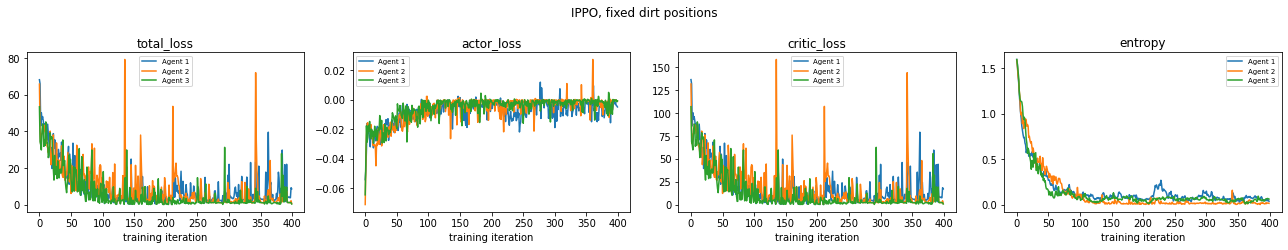

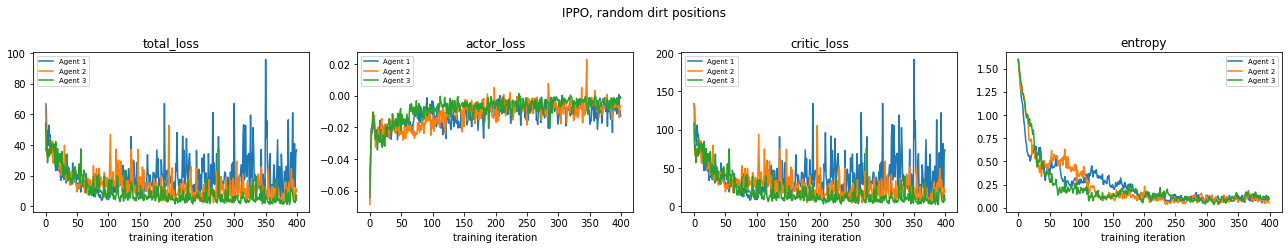

In [16]:
def plot_training_curves(trainer, title):
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
    for ax, m in zip(axes, ["total_loss", "actor_loss", "critic_loss", "entropy"]):
        for i in range(trainer.n_agents):
            ax.plot(trainer.history[i][m], label=f"Agent {i+1}")
        ax.set_title(m)
        ax.set_xlabel("training iteration")
        ax.legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


plot_training_curves(ippo_fixed, "IPPO, fixed dirt positions")
plt.show()
plot_training_curves(ippo_random, "IPPO, random dirt positions")
plt.show()

Performance metrics from training-time episodes: return, length, success rate, safety violation rate.

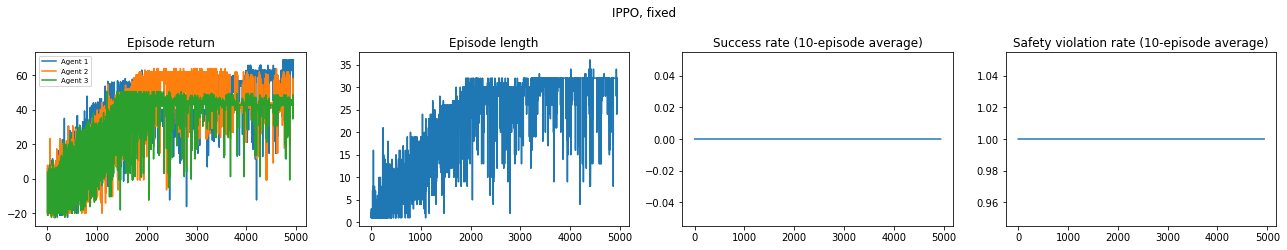

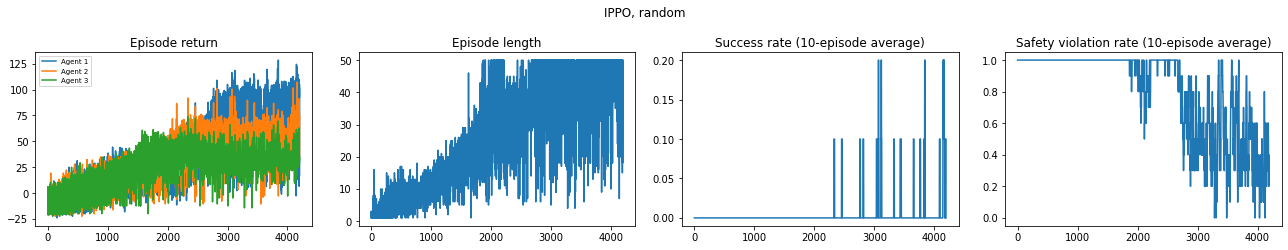

In [17]:
def plot_episode_metrics(trainer, title):
    ret = np.array(trainer.episode_metrics["return"])
    length = np.array(trainer.episode_metrics["length"], dtype=float)
    success = np.array(trainer.episode_metrics["success"], dtype=float)
    violation = np.array(trainer.episode_metrics["violation"], dtype=float)

    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
    for i in range(trainer.n_agents):
        axes[0].plot(ret[:, i], label=f"Agent {i+1}")
    axes[0].set_title("Episode return")
    axes[0].legend(fontsize=7)
    axes[1].plot(length)
    axes[1].set_title("Episode length")
    axes[2].plot(np.convolve(success, np.ones(10) / 10, mode="valid"))
    axes[2].set_title("Success rate (10-episode average)")
    axes[3].plot(np.convolve(violation, np.ones(10) / 10, mode="valid"))
    axes[3].set_title("Safety violation rate (10-episode average)")
    fig.suptitle(title)
    fig.tight_layout()
    return fig


plot_episode_metrics(ippo_fixed, "IPPO, fixed")
plt.show()
plot_episode_metrics(ippo_random, "IPPO, random")
plt.show()

Visual demonstration: load the best checkpoint from disk and execute the actor only (critic detached).

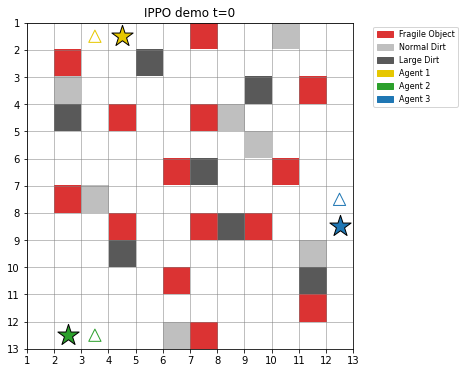

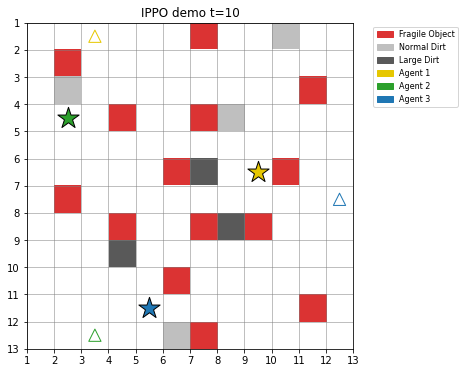

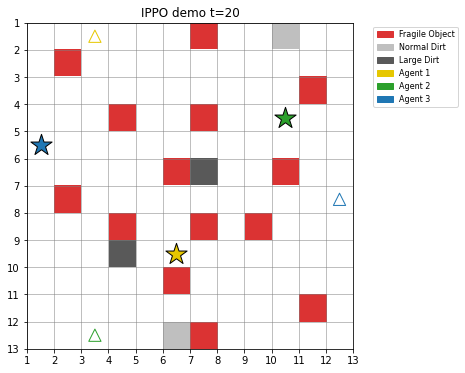

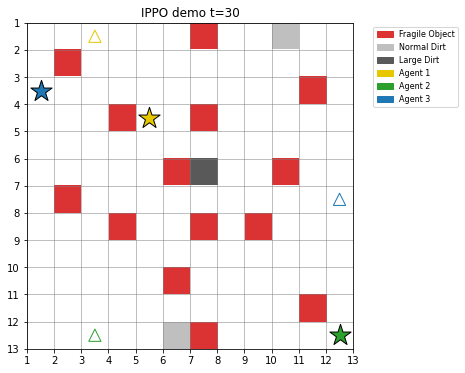

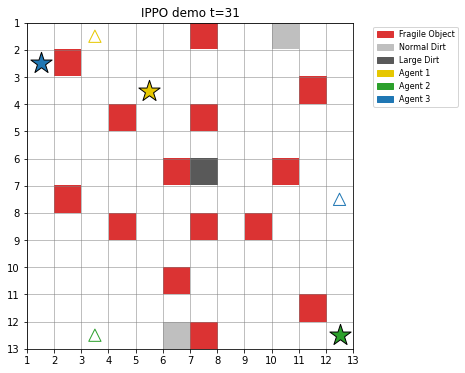

In [18]:
def make_ippo_policy(actors):
    def act_fn(i, obs_flat):
        with torch.no_grad():
            o = torch.tensor(obs_flat, dtype=torch.float32).unsqueeze(0)
            probs = actors[i].forward(o).probs.squeeze(0).numpy()
        return int(np.argmax(probs)), probs
    return act_fn


demo_env = CleaningGridWorld(random_dirt=False, seed=7)
demo_env.reset(seed=7)
demo_actors, _ = load_ippo("checkpoints/ippo_fixed_best", n_agents=demo_env.N_AGENTS, hidden_sizes=(128, 128))
act_fn = make_ippo_policy(demo_actors)
for t in range(demo_env.MAX_STEPS):
    actions = [act_fn(i, demo_env._get_obs()[i].reshape(-1))[0] for i in range(demo_env.N_AGENTS)]
    obs, rewards, terminated, truncated, info = demo_env.step(actions)
    if t % 10 == 0 or terminated or truncated:
        demo_env.render(title=f"IPPO demo t={t}")
        plt.show()
    if terminated or truncated:
        break

## Task 4: Multi-Agent Proximal Policy Optimization (MAPPO)

One parameter-shared actor (local observation plus one-hot agent id) and one
centralized critic over the global state (CTDE, Algorithm 5). Because the
actor/critic are the same module for every agent, all agents' transitions
are pooled into one dataset before the PPO update.

In [19]:
class MAPPOTrainer:
    def __init__(self, random_dirt=False, hidden_sizes=(128, 128), lr_actor=3e-4, lr_critic=3e-4,
                 gamma=0.95, lam=0.95, epsilon=0.2, c1=0.5, c2=0.01, rollout_len=300,
                 minibatch_size=150, k_epochs=8, weight_decay=1e-5, seed=0):
        self.env = CleaningGridWorld(random_dirt=random_dirt, seed=seed)
        self.n_agents = self.env.N_AGENTS
        self.gamma, self.lam = gamma, lam
        self.epsilon, self.c1, self.c2 = epsilon, c1, c2
        self.rollout_len, self.minibatch_size, self.k_epochs = rollout_len, minibatch_size, k_epochs

        torch.manual_seed(seed)
        self.actor, self.critic = build_mappo_networks(self.n_agents, hidden_sizes)
        self.actor_opt = optim.Adam(self.actor.parameters(), lr=lr_actor, weight_decay=weight_decay)
        self.critic_opt = optim.Adam(self.critic.parameters(), lr=lr_critic, weight_decay=weight_decay)

        self.history = {i: {"total_loss": [], "actor_loss": [], "critic_loss": [], "entropy": []} for i in range(self.n_agents)}
        self.episode_metrics = {"return": [], "length": [], "success": [], "violation": []}
        self.best_return, self.best_state = -1e18, None

    def train(self, n_iterations, verbose=True):
        actors_list = [self.actor] * self.n_agents
        critics_list = [self.critic] * self.n_agents

        for it in range(n_iterations):
            buffers, ep_records = collect_rollout(self.env, actors_list, critics_list, self.rollout_len, use_global_state=True)
            for buf in buffers:
                buf.compute_gae(last_value=0.0, gamma=self.gamma, lam=self.lam)

            all_obs, all_value_in, all_actions, all_logp, all_adv, all_ret, all_agent_idx = [], [], [], [], [], [], []
            for i, buf in enumerate(buffers):
                arrs = buf.get_arrays()
                n = len(arrs["actions"])
                all_obs.append(arrs["obs"])
                all_value_in.append(arrs["value_inputs"])
                all_actions.append(arrs["actions"])
                all_logp.append(arrs["log_probs"])
                all_adv.append(arrs["advantages"])
                all_ret.append(arrs["returns"])
                all_agent_idx.append(np.full(n, i))

            obs = torch.tensor(np.concatenate(all_obs), dtype=torch.float32)
            value_in = torch.tensor(np.concatenate(all_value_in), dtype=torch.float32)
            actions = torch.tensor(np.concatenate(all_actions), dtype=torch.int64)
            old_log_probs = torch.tensor(np.concatenate(all_logp), dtype=torch.float32)
            advantages = torch.tensor(np.concatenate(all_adv), dtype=torch.float32)
            returns = torch.tensor(np.concatenate(all_ret), dtype=torch.float32)
            agent_idx = np.concatenate(all_agent_idx)
            actor_in = torch.cat([obs, torch.eye(self.n_agents)[agent_idx]], dim=-1)

            per_agent_losses = {i: {"actor_loss": [], "critic_loss": [], "entropy": [], "total_loss": []} for i in range(self.n_agents)}
            n_total = len(actions)
            for _ in range(self.k_epochs):
                perm = np.random.permutation(n_total)
                for start in range(0, n_total, self.minibatch_size):
                    idx = perm[start:start + self.minibatch_size]
                    if len(idx) < 2:
                        continue
                    batch = {"obs": actor_in[idx], "value_in": value_in[idx], "actions": actions[idx],
                             "old_log_probs": old_log_probs[idx], "advantages": advantages[idx], "returns": returns[idx]}
                    losses = ppo_update(self.actor, self.critic, self.actor_opt, self.critic_opt,
                                         batch, self.epsilon, self.c1, self.c2)
                    for a_id in np.unique(agent_idx[idx]):
                        for k in losses:
                            per_agent_losses[a_id][k].append(losses[k])

            for i in range(self.n_agents):
                for k, v in per_agent_losses[i].items():
                    self.history[i][k].append(float(np.mean(v)) if v else np.nan)

            for rec in ep_records:
                for k in self.episode_metrics:
                    self.episode_metrics[k].append(rec[k])

            if ep_records:
                team_return = np.mean([rec["return"].sum() for rec in ep_records])
                if team_return > self.best_return:
                    self.best_return = team_return
                    self.best_state = copy.deepcopy({"actor": self.actor.state_dict(), "critic": self.critic.state_dict()})

            if verbose and (it % max(1, n_iterations // 10) == 0 or it == n_iterations - 1):
                avg_total = np.nanmean([self.history[i]["total_loss"][-1] for i in range(self.n_agents)])
                print(f"[MAPPO] iter {it+1}/{n_iterations} episodes_in_rollout={len(ep_records)} avg_total_loss={avg_total:.3f}")

    def save_checkpoint(self, path_prefix):
        current = {"actor": self.actor.state_dict(), "critic": self.critic.state_dict()}
        torch.save(current, path_prefix + ".pt")
        torch.save(self.best_state or current, path_prefix + "_best.pt")
        np.savez(path_prefix + "_history.npz",
                 **{f"agent{i}_{k}": np.array(v) for i in range(self.n_agents) for k, v in self.history[i].items()})


def load_mappo(path_prefix, n_agents=3, hidden_sizes=(128, 128)):
    actor, critic = build_mappo_networks(n_agents, hidden_sizes)
    state = torch.load(path_prefix + ".pt", map_location="cpu")
    actor.load_state_dict(state["actor"])
    critic.load_state_dict(state["critic"])
    return actor, critic

Train MAPPO under both dirt-placement modes (same note on `N_ITER` as Task 3).

In [20]:
MAPPO_HPARAMS = dict(hidden_sizes=(128, 128), lr_actor=3e-4, lr_critic=3e-4, gamma=0.95, lam=0.95,
                      epsilon=0.2, c1=0.5, c2=0.01, rollout_len=300, minibatch_size=150, k_epochs=8, weight_decay=1e-5)

mappo_fixed = MAPPOTrainer(random_dirt=False, seed=0, **MAPPO_HPARAMS)
mappo_fixed.train(n_iterations=N_ITER)
mappo_fixed.save_checkpoint("checkpoints/mappo_fixed")

[MAPPO] iter 1/400 episodes_in_rollout=149 avg_total_loss=54.810
[MAPPO] iter 41/400 episodes_in_rollout=15 avg_total_loss=20.411
[MAPPO] iter 81/400 episodes_in_rollout=9 avg_total_loss=21.384
[MAPPO] iter 121/400 episodes_in_rollout=10 avg_total_loss=20.024
[MAPPO] iter 161/400 episodes_in_rollout=10 avg_total_loss=29.690
[MAPPO] iter 201/400 episodes_in_rollout=8 avg_total_loss=16.084
[MAPPO] iter 241/400 episodes_in_rollout=9 avg_total_loss=30.726
[MAPPO] iter 281/400 episodes_in_rollout=9 avg_total_loss=22.105
[MAPPO] iter 321/400 episodes_in_rollout=8 avg_total_loss=20.815
[MAPPO] iter 361/400 episodes_in_rollout=9 avg_total_loss=16.171
[MAPPO] iter 400/400 episodes_in_rollout=10 avg_total_loss=24.361


In [21]:
mappo_random = MAPPOTrainer(random_dirt=True, seed=0, **MAPPO_HPARAMS)
mappo_random.train(n_iterations=N_ITER)
mappo_random.save_checkpoint("checkpoints/mappo_random")

[MAPPO] iter 1/400 episodes_in_rollout=149 avg_total_loss=54.139
[MAPPO] iter 41/400 episodes_in_rollout=14 avg_total_loss=21.444
[MAPPO] iter 81/400 episodes_in_rollout=10 avg_total_loss=15.744
[MAPPO] iter 121/400 episodes_in_rollout=9 avg_total_loss=22.444
[MAPPO] iter 161/400 episodes_in_rollout=9 avg_total_loss=30.039
[MAPPO] iter 201/400 episodes_in_rollout=7 avg_total_loss=8.883
[MAPPO] iter 241/400 episodes_in_rollout=6 avg_total_loss=9.381
[MAPPO] iter 281/400 episodes_in_rollout=6 avg_total_loss=9.507
[MAPPO] iter 321/400 episodes_in_rollout=6 avg_total_loss=11.881
[MAPPO] iter 361/400 episodes_in_rollout=9 avg_total_loss=26.078
[MAPPO] iter 400/400 episodes_in_rollout=6 avg_total_loss=10.748


Training curves and performance metrics for MAPPO (reusing the plot functions from Task 3).

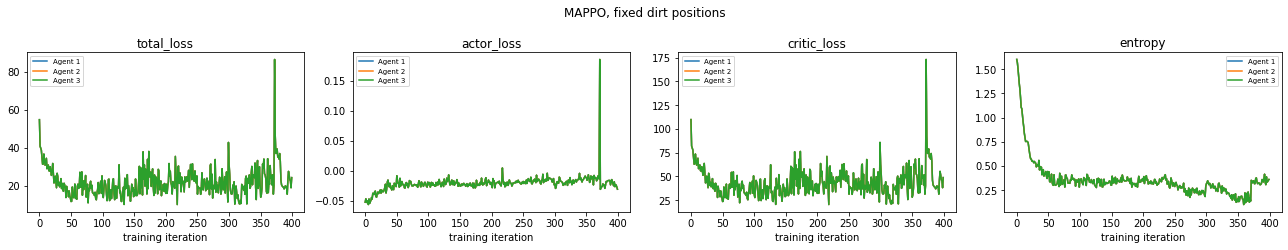

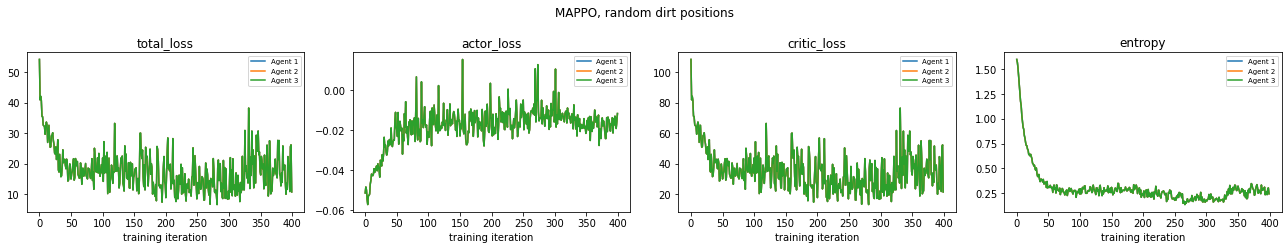

In [22]:
plot_training_curves(mappo_fixed, "MAPPO, fixed dirt positions")
plt.show()
plot_training_curves(mappo_random, "MAPPO, random dirt positions")
plt.show()

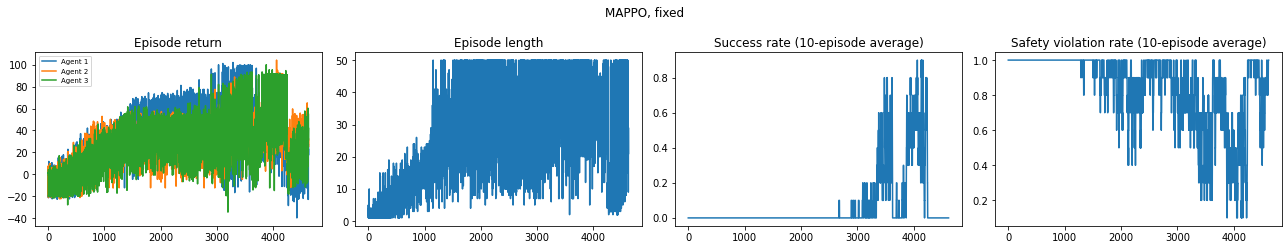

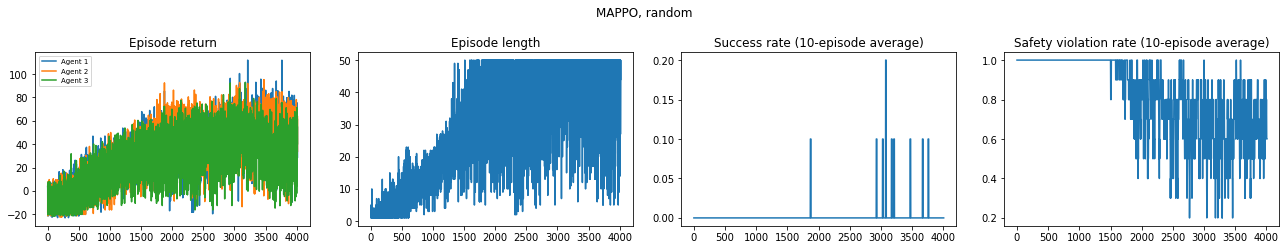

In [23]:
plot_episode_metrics(mappo_fixed, "MAPPO, fixed")
plt.show()
plot_episode_metrics(mappo_random, "MAPPO, random")
plt.show()

Visual demonstration: load the best MAPPO checkpoint from disk and execute the actor only.

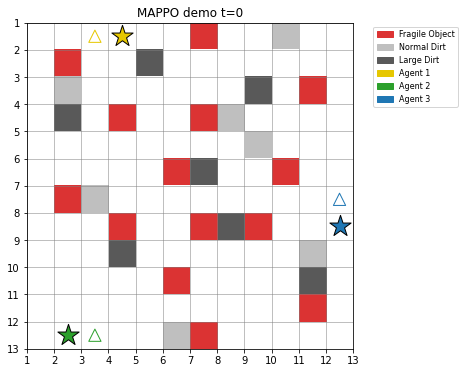

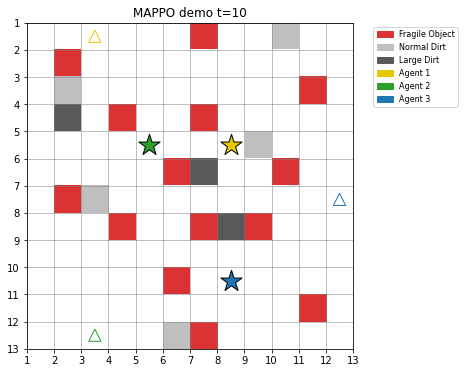

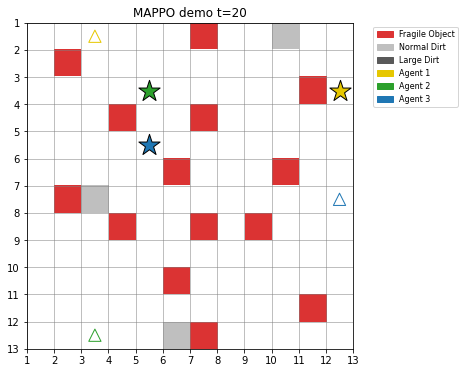

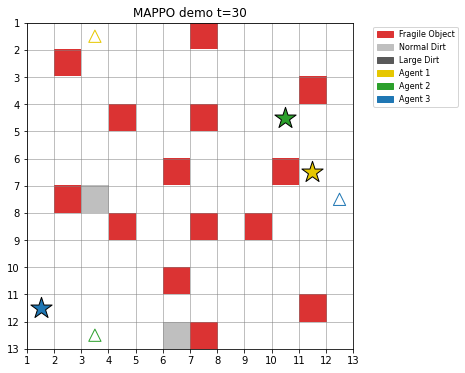

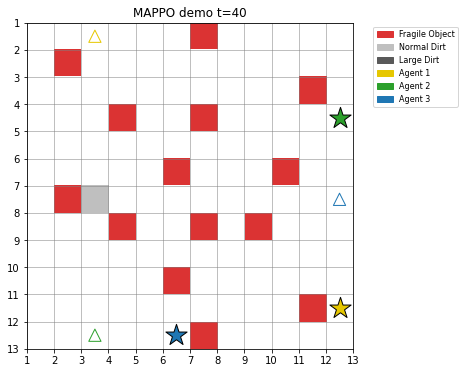

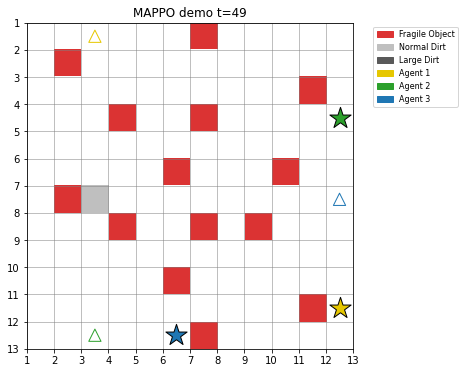

In [24]:
def make_mappo_policy(actor, n_agents):
    eye = torch.eye(n_agents)

    def act_fn(i, obs_flat):
        with torch.no_grad():
            o = torch.tensor(obs_flat, dtype=torch.float32).unsqueeze(0)
            actor_in = torch.cat([o, eye[i].unsqueeze(0)], dim=-1)
            probs = actor.forward(actor_in).probs.squeeze(0).numpy()
        return int(np.argmax(probs)), probs
    return act_fn


demo_env = CleaningGridWorld(random_dirt=False, seed=7)
demo_env.reset(seed=7)
demo_actor, _ = load_mappo("checkpoints/mappo_fixed_best", n_agents=demo_env.N_AGENTS, hidden_sizes=(128, 128))
act_fn = make_mappo_policy(demo_actor, demo_env.N_AGENTS)
for t in range(demo_env.MAX_STEPS):
    actions = [act_fn(i, demo_env._get_obs()[i].reshape(-1))[0] for i in range(demo_env.N_AGENTS)]
    obs, rewards, terminated, truncated, info = demo_env.step(actions)
    if t % 10 == 0 or terminated or truncated:
        demo_env.render(title=f"MAPPO demo t={t}")
        plt.show()
    if terminated or truncated:
        break

## Task 5: Comprehensive Evaluation

Compare IPPO vs MAPPO, fixed vs random dirt placement, on generalization,
task efficiency/coordination, agent contribution, and behavioural diversity.

Evaluation rollout: runs one episode with a given policy, tracking visited cells, action probabilities, and advantage-based contribution.

In [25]:
def make_value_fn_ippo(critics):
    def value_fn(i, value_input):
        with torch.no_grad():
            return float(critics[i](torch.tensor(value_input, dtype=torch.float32).unsqueeze(0)).item())
    return value_fn


def make_value_fn_mappo(critic):
    def value_fn(i, value_input):
        with torch.no_grad():
            return float(critic(torch.tensor(value_input, dtype=torch.float32).unsqueeze(0)).item())
    return value_fn


def rollout_episode(env, act_fn, value_fn=None, use_global_state=False, gamma=0.95, max_steps=50):
    obs_list, _ = env.reset()
    visit_map = np.zeros((env.GRID, env.GRID), dtype=int)
    revisit_map = np.zeros((env.GRID, env.GRID), dtype=int)
    prob_log = {i: [] for i in range(env.N_AGENTS)}
    contribution = np.zeros(env.N_AGENTS)
    ep_return = np.zeros(env.N_AGENTS)
    violation, terminated, length = False, False, 0

    for t in range(max_steps):
        pre_explored = env.explored.copy()
        flat_obs = [o.reshape(-1) for o in obs_list]
        value_in_pre = env.get_global_state().reshape(-1) if use_global_state else None

        actions, v_pre = [], np.zeros(env.N_AGENTS)
        for i in range(env.N_AGENTS):
            a, probs = act_fn(i, flat_obs[i])
            actions.append(a)
            prob_log[i].append(probs)
            if value_fn is not None:
                v_in = value_in_pre if use_global_state else flat_obs[i]
                v_pre[i] = value_fn(i, v_in)

        obs_list, rewards, terminated, truncated, info = env.step(actions)
        ep_return += rewards
        length += 1
        if info["collided"].any():
            violation = True

        if value_fn is not None:
            next_flat_obs = [o.reshape(-1) for o in obs_list]
            next_global = env.get_global_state().reshape(-1) if use_global_state else None
            for i in range(env.N_AGENTS):
                v_in_next = next_global if use_global_state else next_flat_obs[i]
                contribution[i] += rewards[i] + gamma * value_fn(i, v_in_next) - v_pre[i]

        for i, (r, c) in enumerate(env.agent_pos):
            if info["collided"][i]:
                continue
            visit_map[r, c] += 1
            if pre_explored[r, c]:
                revisit_map[r, c] += 1

        if terminated or truncated:
            break

    return {"return": ep_return, "length": length, "success": bool(terminated), "violation": violation,
            "visit_map": visit_map, "revisit_map": revisit_map, "prob_log": prob_log, "contribution": contribution}


def evaluate_policy(env, act_fn, value_fn=None, use_global_state=False, n_episodes=400, gamma=0.95, seed=123):
    results = {"return": [], "length": [], "success": [], "violation": [], "contribution": [],
               "prob_sum": {i: np.zeros(5) for i in range(env.N_AGENTS)}, "prob_count": {i: 0 for i in range(env.N_AGENTS)}}
    visit_total = np.zeros((env.GRID, env.GRID), dtype=int)
    revisit_total = np.zeros((env.GRID, env.GRID), dtype=int)

    for ep in range(n_episodes):
        env.reset(seed=seed + ep)
        rec = rollout_episode(env, act_fn, value_fn, use_global_state, gamma, max_steps=env.MAX_STEPS)
        results["return"].append(rec["return"])
        results["length"].append(rec["length"] if rec["success"] else np.nan)
        results["success"].append(rec["success"])
        results["violation"].append(rec["violation"])
        results["contribution"].append(rec["contribution"])
        visit_total += rec["visit_map"]
        revisit_total += rec["revisit_map"]
        for i in range(env.N_AGENTS):
            for p in rec["prob_log"][i]:
                results["prob_sum"][i] += p
                results["prob_count"][i] += 1

    results["return"] = np.array(results["return"])
    results["success"] = np.array(results["success"])
    results["violation"] = np.array(results["violation"])
    results["contribution"] = np.array(results["contribution"])
    results["visit_total"], results["revisit_total"] = visit_total, revisit_total
    results["avg_action_dist"] = {i: results["prob_sum"][i] / max(1, results["prob_count"][i]) for i in range(env.N_AGENTS)}
    return results

Load each best checkpoint from disk (actor + critic, so contribution can also be
computed) and evaluate on 400 unseen random-dirt episodes with a fresh seed.

In [26]:
N_EVAL_EPISODES = 400
EVAL_SEED = 2026
eval_env = CleaningGridWorld(random_dirt=True, seed=EVAL_SEED)
n = eval_env.N_AGENTS

ippo_fixed_actors, ippo_fixed_critics = load_ippo("checkpoints/ippo_fixed_best", n, (128, 128))
ippo_random_actors, ippo_random_critics = load_ippo("checkpoints/ippo_random_best", n, (128, 128))
mappo_fixed_actor, mappo_fixed_critic = load_mappo("checkpoints/mappo_fixed_best", n, (128, 128))
mappo_random_actor, mappo_random_critic = load_mappo("checkpoints/mappo_random_best", n, (128, 128))

configs = {
    "IPPO-fixed":  (make_ippo_policy(ippo_fixed_actors),  make_value_fn_ippo(ippo_fixed_critics), False),
    "IPPO-random": (make_ippo_policy(ippo_random_actors), make_value_fn_ippo(ippo_random_critics), False),
    "MAPPO-fixed":  (make_mappo_policy(mappo_fixed_actor, n),  make_value_fn_mappo(mappo_fixed_critic), True),
    "MAPPO-random": (make_mappo_policy(mappo_random_actor, n), make_value_fn_mappo(mappo_random_critic), True),
}

eval_results = {}
for name, (act_fn, value_fn, use_global) in configs.items():
    eval_results[name] = evaluate_policy(eval_env, act_fn, value_fn, use_global_state=use_global,
                                          n_episodes=N_EVAL_EPISODES, seed=EVAL_SEED)
    res = eval_results[name]
    print(f"{name}: success_rate={res['success'].mean()*100:.1f}% violation_rate={res['violation'].mean()*100:.1f}% "
          f"avg_ep_length={np.nanmean(res['length']):.1f} avg_team_return={res['return'].sum(axis=1).mean():.2f}")

C:\Users\lenovo\AppData\Local\Temp\ipykernel_30972\3622791823.py:24: RuntimeWarning: Mean of empty slice
  f"avg_ep_length={np.nanmean(res['length']):.1f} avg_team_return={res['return'].sum(axis=1).mean():.2f}")


IPPO-fixed: success_rate=0.0% violation_rate=100.0% avg_ep_length=nan avg_team_return=145.49
IPPO-random: success_rate=1.0% violation_rate=99.0% avg_ep_length=35.5 avg_team_return=161.44
MAPPO-fixed: success_rate=0.5% violation_rate=0.0% avg_ep_length=36.0 avg_team_return=131.81
MAPPO-random: success_rate=1.2% violation_rate=0.0% avg_ep_length=37.6 avg_team_return=170.33


5.1a Generalization: success rate and team return across the sequence of 400 test episodes (rolling average, window 20).

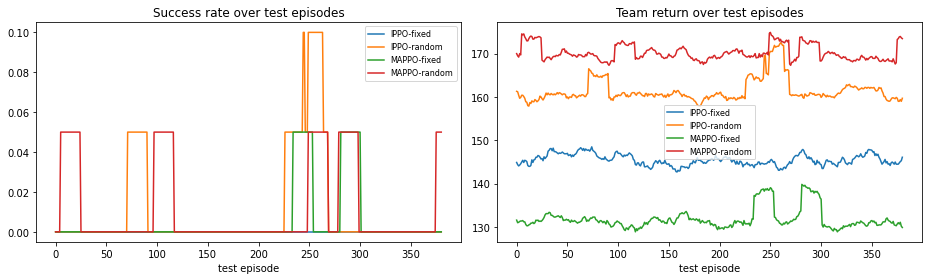

In [27]:
window = 20
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, res in eval_results.items():
    axes[0].plot(np.convolve(res["success"].astype(float), np.ones(window) / window, mode="valid"), label=name)
    axes[1].plot(np.convolve(res["return"].sum(axis=1), np.ones(window) / window, mode="valid"), label=name)
axes[0].set_title("Success rate over test episodes"); axes[0].set_xlabel("test episode"); axes[0].legend(fontsize=8)
axes[1].set_title("Team return over test episodes"); axes[1].set_xlabel("test episode"); axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

5.1b Generalization: box plots of success rate (in 20-episode blocks), team return, and per-agent return.

C:\Users\lenovo\AppData\Local\Temp\ipykernel_30972\3086972754.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([block_mean(eval_results[k]["success"].astype(float)) * 100 for k in labels], labels=labels)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_30972\3086972754.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([eval_results[k]["return"].sum(axis=1) for k in labels], labels=labels)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_30972\3086972754.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([eval_results[k]["return"][:, i] for k in labels for i in range(n)],

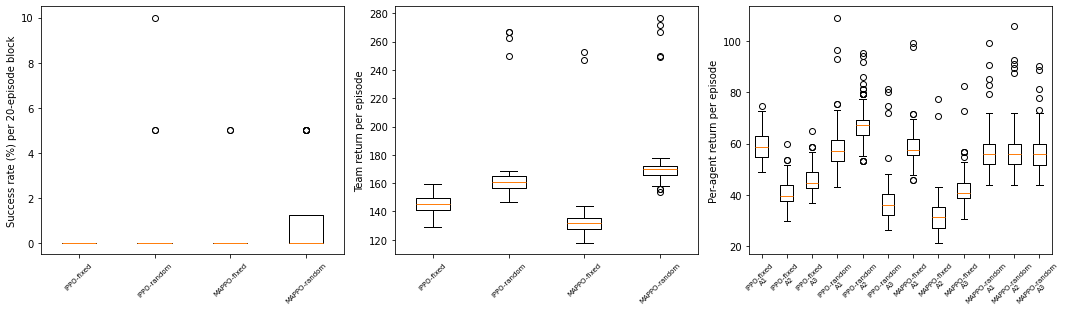

In [28]:
def block_mean(x, block=20):
    n = len(x) // block
    return x[:n * block].reshape(n, block).mean(axis=1)


labels = list(eval_results.keys())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].boxplot([block_mean(eval_results[k]["success"].astype(float)) * 100 for k in labels], labels=labels)
axes[0].set_ylabel("Success rate (%) per 20-episode block")
axes[1].boxplot([eval_results[k]["return"].sum(axis=1) for k in labels], labels=labels)
axes[1].set_ylabel("Team return per episode")
axes[2].boxplot([eval_results[k]["return"][:, i] for k in labels for i in range(n)],
                labels=[f"{k}\nA{i+1}" for k in labels for i in range(n)])
axes[2].set_ylabel("Per-agent return per episode")
for a in axes:
    a.tick_params(axis="x", rotation=45, labelsize=7)
fig.tight_layout()
plt.show()

5.2 Task efficiency and coordination: Global Redundant Coverage Ratio and the per-cell RCR heatmap.

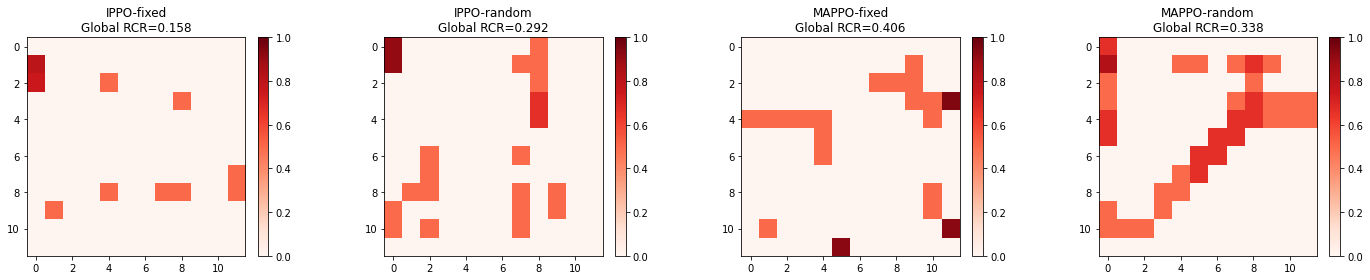

In [29]:
def global_rcr(visit_total, revisit_total):
    return float(revisit_total.sum() / max(1, visit_total.sum()))


def rcr_map(visit_total, revisit_total):
    out = np.zeros_like(visit_total, dtype=float)
    mask = visit_total > 0
    out[mask] = revisit_total[mask] / visit_total[mask]
    return out


fig, axes = plt.subplots(1, len(eval_results), figsize=(5 * len(eval_results), 4))
for ax, (name, res) in zip(axes, eval_results.items()):
    grcr = global_rcr(res["visit_total"], res["revisit_total"])
    rmap = rcr_map(res["visit_total"], res["revisit_total"])
    im = ax.imshow(rmap, cmap="Reds", vmin=0, vmax=1)
    ax.set_title(f"{name}\nGlobal RCR={grcr:.3f}")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

5.3 Agent contribution: mean advantage-based contribution per agent per episode.

In [30]:
for name, res in eval_results.items():
    print(f"{name}: mean contribution per agent = {np.round(res['contribution'].mean(axis=0), 3)}")

IPPO-fixed: mean contribution per agent = [ -1.959 -20.963   4.631]
IPPO-random: mean contribution per agent = [-17.906   4.732  -2.536]
MAPPO-fixed: mean contribution per agent = [ -9.727 -37.231 -26.422]
MAPPO-random: mean contribution per agent = [-2.428 -2.395 -2.521]


5.4 Behavioural diversity: pairwise Jensen-Shannon Divergence between the 3 agents' average action distributions.

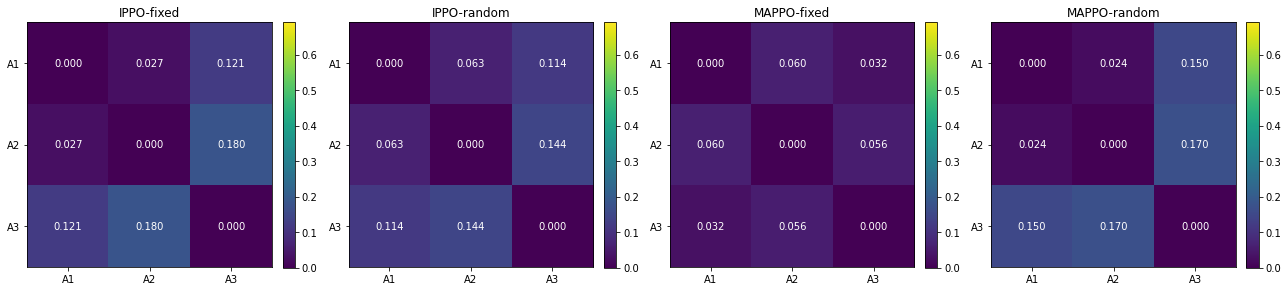

In [31]:
def kl_divergence(p, q, eps=1e-10):
    p, q = np.clip(p, eps, 1), np.clip(q, eps, 1)
    return float(np.sum(p * np.log(p / q)))


def jensen_shannon(p, q):
    m = 0.5 * (p + q)
    return 0.5 * kl_divergence(p, m) + 0.5 * kl_divergence(q, m)


def jsd_matrix(dists):
    idxs = sorted(dists.keys())
    n = len(idxs)
    mat = np.zeros((n, n))
    for a in range(n):
        for b in range(n):
            mat[a, b] = jensen_shannon(dists[idxs[a]], dists[idxs[b]])
    return mat


fig, axes = plt.subplots(1, len(eval_results), figsize=(4.5 * len(eval_results), 4))
for ax, (name, res) in zip(axes, eval_results.items()):
    mat = jsd_matrix(res["avg_action_dist"])
    im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=np.log(2))
    n = mat.shape[0]
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels([f"A{i+1}" for i in range(n)])
    ax.set_yticklabels([f"A{i+1}" for i in range(n)])
    for a in range(n):
        for b in range(n):
            ax.text(b, a, f"{mat[a, b]:.3f}", ha="center", va="center",
                    color="white" if mat[a, b] < np.log(2) / 2 else "black")
    ax.set_title(name)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

## Discussion notes (for the oral session)

- Learning performance: which method converges faster or more stably, and why
  (independent non-stationarity vs. centralized-critic variance reduction).
- Task efficiency: does MAPPO's centralized critic lower Global RCR compared
  to IPPO, i.e. did agents learn to partition the map instead of overlapping.
- Coordination failures: check whether high-violation episodes are
  agent-agent collisions (credit assignment) or fragile-object hits
  (exploration), and whether that differs between IPPO and MAPPO.
- Behavioural diversity: does MAPPO's parameter sharing make the 3 agents'
  policies more similar (lower JSD) than IPPO's independent networks, and is
  that helpful or harmful for this cooperative task.